In [110]:
import ROOT

import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as interp
import scipy.optimize as opt
import matplotlib as mpl
import scipy.special as sf
import scipy.integrate as integ
import scipy.linalg as la
mpl.rc('xtick', direction='in', top=True)
mpl.rc('ytick', direction='in', right=True)
mpl.rc('xtick.minor', visible=True)
mpl.rc('ytick.minor', visible=True)
import pandas as pd
import glob
import os
import re



In [111]:
file=ROOT.TFile.Open('first set sent/results-20251118T165745Z-1-001/results/Seed600_Angle88.0000000_Pos0.0010000_Energy18600.000000/basic_Angle88.0000000_Pos0.0010000_Energy18600.000000.root','READ')

In [112]:
file.ls()


TFile**		first set sent/results-20251118T165745Z-1-001/results/Seed600_Angle88.0000000_Pos0.0010000_Energy18600.000000/basic_Angle88.0000000_Pos0.0010000_Energy18600.000000.root	
 TFile*		first set sent/results-20251118T165745Z-1-001/results/Seed600_Angle88.0000000_Pos0.0010000_Energy18600.000000/basic_Angle88.0000000_Pos0.0010000_Energy18600.000000.root	
  KEY: TH1D	histPSD_0_0;2	Power Spectrum [current cycle]
  KEY: TH1D	histPSD_0_0;1	Power Spectrum [backup cycle]
  KEY: TH1D	histFSfftwPhase_0_0;2	Frequency Spectrum: Phase [current cycle]
  KEY: TH1D	histFSfftwPhase_0_0;1	Frequency Spectrum: Phase [backup cycle]
  KEY: TH1D	histTSReal_0_0;2	Time Series [current cycle]
  KEY: TH1D	histTSReal_0_0;1	Time Series [backup cycle]
  KEY: TH1D	histTSImag_0_0;2	Time Series [current cycle]
  KEY: TH1D	histTSImag_0_0;1	Time Series [backup cycle]
  KEY: TH1D	histPSD_1_0;2	Power Spectrum [current cycle]
  KEY: TH1D	histPSD_1_0;1	Power Spectrum [backup cycle]
  KEY: TH1D	histFSfftwPhase_1_0;2	Frequ

In [113]:
hist=file.Get("histFSfftwPhase_0_0")

In [114]:
for i in range(1, hist.GetNbinsX() + 1):
    x = hist.GetBinCenter(i)
    y = hist.GetBinContent(i)
    print(x, y)

0.0 1.5707963267948744
49194.3359375 1.579920114003261
98388.671875 1.5888822615068174
147583.0078125 1.5976808251425643
196777.34375 1.6063141505811065
245971.6796875 1.6147808636510461
295166.015625 1.6230798600731604
344360.3515625 1.6312102947117673
393554.6875 1.6391715704459682
442749.0234375 1.6469633267573436
491943.359375 1.6545854281247234
541137.6953125 1.662037952309857
590332.03125 1.669321178610991
639526.3671875 1.676435576154499
688720.703125 1.6833817922876488
737915.0390625 1.6901606411287171
787109.375 1.6967730923243194
836303.7109375 1.7032202600567883
885498.046875 1.7095033923388687
934692.3828125 1.7156238606268173
983886.71875 1.7215831497777505
1033081.0546875 1.7273828483718279
1082275.390625 1.7330246394153341
1131469.7265625 1.7385102914365427
1180664.0625 1.7438416499818201
1229858.3984375 1.7490206295168451
1279052.734375 1.754049205733797
1328247.0703125 1.7589294082630922
1377441.40625 1.7636633137859432
1426635.7421875 1.768253039541463
1475830.078125 

In [115]:
base_path = "first set sent/Results_rootonly"
index = {}

for angle_dir in os.listdir(base_path):
    angle_path = os.path.join(base_path, angle_dir)

    if not os.path.isdir(angle_path):
        continue

    angle = angle_dir
    index[angle] = {}

    for filepath in glob.glob(os.path.join(angle_path, "*.root")):
        fname = os.path.basename(filepath)

        match = re.search(r'(Pos[\d.]+)', fname)

        if match is None:
            print(f"Could not find position in filename: {fname}")
            continue
        
        position = match.group(1)

        file = ROOT.TFile.Open(filepath)

        index[angle][position] = {}

        for key in file.GetListOfKeys():
            hist_name = key.GetName()
            obj = key.ReadObj()

            if obj.InheritsFrom("TH1"):
                index[angle][position][hist_name] = {
                    "filepath": filepath,
                    "class": obj.ClassName()
                }

        file.Close()


In [135]:
index['angle90.00']['Pos0.0010000']

{'histPSD_0_0': {'filepath': 'first set sent/Results_rootonly/angle90.00/basic_Angle90.0000000_Pos0.0010000_Energy18600.000000.root',
  'class': 'TH1D'},
 'histFSfftwPhase_0_0': {'filepath': 'first set sent/Results_rootonly/angle90.00/basic_Angle90.0000000_Pos0.0010000_Energy18600.000000.root',
  'class': 'TH1D'},
 'histTSReal_0_0': {'filepath': 'first set sent/Results_rootonly/angle90.00/basic_Angle90.0000000_Pos0.0010000_Energy18600.000000.root',
  'class': 'TH1D'},
 'histTSImag_0_0': {'filepath': 'first set sent/Results_rootonly/angle90.00/basic_Angle90.0000000_Pos0.0010000_Energy18600.000000.root',
  'class': 'TH1D'},
 'histPSD_1_0': {'filepath': 'first set sent/Results_rootonly/angle90.00/basic_Angle90.0000000_Pos0.0010000_Energy18600.000000.root',
  'class': 'TH1D'},
 'histFSfftwPhase_1_0': {'filepath': 'first set sent/Results_rootonly/angle90.00/basic_Angle90.0000000_Pos0.0010000_Energy18600.000000.root',
  'class': 'TH1D'},
 'histTSReal_1_0': {'filepath': 'first set sent/Result

In [117]:
def process_hist(base_path, angle, position, hist_name, func):
    hist_info = index[angle][position][hist_name]
    filepath = hist_info["filepath"]
    file = ROOT.TFile.Open(filepath)
    hist = file.Get(hist_name)

    if not hist:
        print("Missing:", hist_name)
        file.Close()
        return

    # apply user-defined function
    func(hist)

    file.Close()

In [118]:
def plot_hist_bar(hist, ax):
    nbins = hist.GetNbinsX()

    x = np.empty(nbins)
    y = np.empty(nbins)
    width = np.empty(nbins)

    for i in range(1, nbins + 1):
        x[i-1] = hist.GetBinCenter(i)
        y[i-1] = hist.GetBinContent(i)
        width[i-1] = hist.GetBinWidth(i)

    ax.bar(x, y, width=width)
def plot_wrapper(hist):
    fig, ax = plt.subplots()
    plot_hist_bar(hist, ax)
    plt.show()


In [ ]:
def print_hist(hist):
    for i in range(1, hist.GetNbinsX() + 1):
        print(hist.GetBinCenter(i), hist.GetBinContent(i))

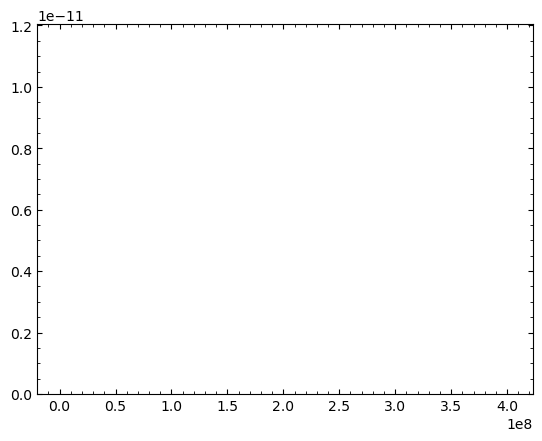

In [137]:
process_hist(
    base_path,
    "angle89.75",
    "Pos0.0010000",
    "histPSD_0_0",
    plot_wrapper
)

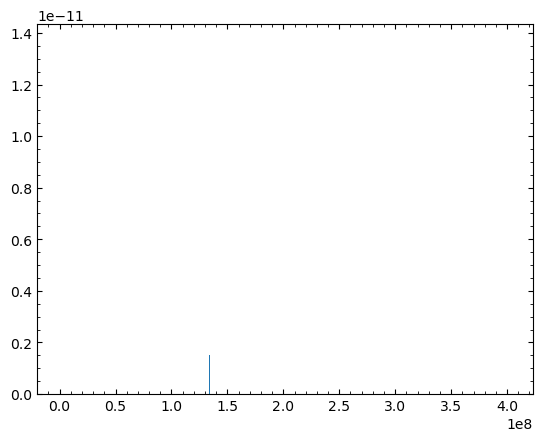

In [134]:
process_hist(
    base_path,
    "angle90.00",
    "Pos0.0020000",
    "histPSD_0_0",
    plot_wrapper
)